# Deriving the ω₅₀₀ field and defining analysis regions

This supplementary notebook derives the time-mean vertical pressure velocity at 500 hPa (ω₅₀₀) from the monthly CESM2 piControl output. The resulting field is used to document and visualise the three regional boxes used in the analysis.

The calculation is performed only when `wap_500_mean.nc` does not exist (or when `overwrite` is set to `True`). Otherwise, the saved result is loaded directly.

## Config

In [ ]:
import pathlib

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import cartopy.crs as ccrs
import matplotlib.patheffects as patheffects

from functions import regions

raw_wap_dir = pathlib.Path('/climca/data/CESM2_LE_mon/piControl/wap')
data_dir = pathlib.Path('/path/to/data/piControl')  # change to your data directory
output_path = data_dir / "wap_500_mean.nc"

overwrite = False
spinup_years = 100
omega_step = 6              # hPa/day per colour class
omega_classes = 21
projection = ccrs.EqualEarth(central_longitude=180)
cmap = "RdBu_r"              # positive omega = descent


## Derive or load the mean ω₅₀₀ field

In [5]:
if output_path.exists() and not overwrite:
    omega500_mean = xr.open_dataarray(output_path)
    print(f"Loaded {output_path}")
else:
    wap_paths = sorted(raw_wap_dir.glob("*.nc"))
    if not wap_paths:
        raise FileNotFoundError(f"No monthly WAP files found in {raw_wap_dir}")

    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    with xr.open_mfdataset(
        wap_paths,
        combine="by_coords",
        decode_times=time_coder,
        chunks={"time": 240, "lat": 96, "lon": 96},
    ) as ds:
        omega500 = ds["wap"].sel(plev=50000, method="nearest")
        omega500 = omega500 * 864  # Pa/s -> hPa/day
        omega500.attrs["units"] = "hPa/day"
        omega500_mean = (
            omega500.resample(time="YS").mean()
            .isel(time=slice(spinup_years, None))
            .mean(dim="time")
            .compute()
        )

    output_path.parent.mkdir(parents=True, exist_ok=True)
    omega500_mean.to_netcdf(output_path)
    print(f"Saved {output_path}")


Loaded /Users/liobabraun/Desktop/Uni_Leipzig/MA/server/data/piControl/wap_500_mean.nc


## Mean ω₅₀₀ and analysis regions

Negative values indicate ascent and positive values indicate descent.

/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


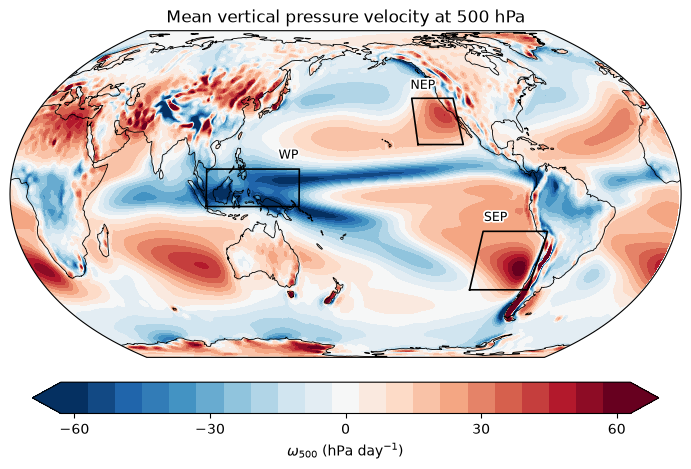

In [8]:
levels = (np.arange(-(omega_classes // 2), omega_classes // 2 + 2) - 0.5) * omega_step
norm = BoundaryNorm(levels, ncolors=plt.get_cmap(cmap).N, clip=False)

fig = plt.figure(figsize=(9, 4.8))
ax = fig.add_subplot(projection=projection)
mesh = ax.contourf(
    omega500_mean["lon"],
    omega500_mean["lat"],
    omega500_mean,
    levels=levels,
    cmap=cmap,
    norm=norm,
    extend="both",
    transform=ccrs.PlateCarree(),
)

ax.coastlines(linewidth=0.6, zorder=4)
ax.set_global()

# Optional contour lines for the ascent/descent boundaries:
# omega500_mean.plot.contour(
#     ax=ax,
#     transform=ccrs.PlateCarree(),
#     levels=[-30, 30],
#     colors=["navy", "darkred"],
#     linewidths=1,
# )

label_effect = [patheffects.withStroke(linewidth=2.5, foreground="white")]
short_names = {
    "southeastern_pacific": "SEP",
    "northeastern_pacific": "NEP",
    "western_pacific": "WP",
}
for name, box in regions.items():
    (lat_min, lat_max), (lon_min, lon_max) = box["lat"], box["lon"]
    ax.plot(
        [lon_min, lon_max, lon_max, lon_min, lon_min],
        [lat_min, lat_min, lat_max, lat_max, lat_min],
        color="black",
        linewidth=1.2,
        transform=ccrs.PlateCarree(),
        zorder=5,
    )
    ax.text(
        lon_max if name == "western_pacific" else lon_min,
        lat_max + 3,
        short_names[name],
        ha="right" if name == "western_pacific" else "left",
        va="bottom",
        fontsize=9,
        transform=ccrs.PlateCarree(),
        path_effects=label_effect,
        zorder=6,
    )

ticks = np.arange(-60, 61, 30)
cbar = fig.colorbar(mesh, ax=ax, orientation="horizontal", ticks=ticks, pad=0.06, shrink=0.72)
cbar.set_label(r"$\omega_{500}$ (hPa day$^{-1}$)")
cbar.ax.minorticks_off()
ax.set_title("Mean vertical pressure velocity at 500 hPa")
fig.tight_layout()

plt.show()
